<a href="https://colab.research.google.com/github/Vickysatria313/Transfer_Learning_Assignment/blob/main/EfficientNet_B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:

from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive.zip


In [3]:

import zipfile
import os

zip_name = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content/dataset")

print("Dataset berhasil diekstrak.")
print(os.listdir("/content/dataset"))


Dataset berhasil diekstrak.
['val', 'test', 'train']


In [4]:

import os

BASE_DIR = "/content/dataset"

for split in ["train", "val", "test"]:
    split_path = os.path.join(BASE_DIR, split)

    print(f"\nFolder {split}:")
    for item in os.listdir(split_path):
        item_path = os.path.join(split_path, item)

        if os.path.isdir(item_path):
            print(f"  {item}: {len(os.listdir(item_path))} file")
        else:
            print(f"  File: {item}")



Folder train:
  labels: 3900 file
  images: 3900 file

Folder val:
  labels: 1300 file
  images: 1300 file

Folder test:
  labels: 1300 file
  images: 1300 file


In [5]:

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{BASE_DIR}/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{BASE_DIR}/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{BASE_DIR}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Daftar kelas:", class_names)
print("Jumlah kelas:", num_classes)
print("GPU:", tf.config.list_physical_devices("GPU"))


Found 3900 files belonging to 2 classes.
Found 1300 files belonging to 2 classes.
Found 1300 files belonging to 2 classes.
Daftar kelas: ['images', 'labels']
Jumlah kelas: 2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:

import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:

import os

BASE_DIR = "/content/dataset"

for split in ["train", "val", "test"]:
    print(f"{split}:")
    print(os.listdir(os.path.join(BASE_DIR, split)))


train:
['labels', 'images']
val:
['labels', 'images']
test:
['labels', 'images']


In [8]:

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{BASE_DIR}/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{BASE_DIR}/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{BASE_DIR}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Kelas:", class_names)
print("Jumlah kelas:", num_classes)


Found 3900 files belonging to 2 classes.
Found 1300 files belonging to 2 classes.
Found 1300 files belonging to 2 classes.
Kelas: ['images', 'labels']
Jumlah kelas: 2


In [9]:

from tensorflow import keras
from tensorflow.keras import layers

base_model = keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

# EfficientNetB0 Keras memiliki preprocessing input bawaan
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,052,133 (15.46 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [10]:

import time
import os

os.makedirs("/content/results", exist_ok=True)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)

training_time = time.time() - start_time

print(f"Waktu training: {training_time:.2f} detik")


Epoch 1/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 84s 445ms/step - accuracy: 0.9833 - loss: 0.0543 - val_accuracy: 0.9992 - val_loss: 0.0069
Epoch 2/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 30s 249ms/step - accuracy: 1.0000 - loss: 0.0049 - val_accuracy: 0.9992 - val_loss: 0.0035
Epoch 3/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 40s 240ms/step - accuracy: 1.0000 - loss: 0.0025 - val_accuracy: 0.9992 - val_loss: 0.0024
Epoch 4/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 42s 250ms/step - accuracy: 1.0000 - loss: 0.0016 - val_accuracy: 0.9992 - val_loss: 0.0019
Epoch 5/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 41s 250ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 0.9992 - val_loss: 0.0017
Epoch 6/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 40s 240ms/step - accuracy: 1.0000 - loss: 8.2971e-04 - val_accuracy: 0.9992 - val_loss: 0.0015
Epoch 7/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 30s 248ms/step - accuracy: 1.0000 - loss: 6.9958e-04 - val_accuracy: 0.9992 - val_loss: 0.0014
Epoch 8/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 26s 213ms/step - accuracy: 1.0000 -

In [11]:

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


41/41 ━━━━━━━━━━━━━━━━━━━━ 9s 209ms/step - accuracy: 1.0000 - loss: 3.2622e-04
Test Accuracy: 100.00%
Test Loss: 0.0003


In [12]:

model.save("/content/results/EfficientNetB0.keras")

print("Model berhasil disimpan.")


Model berhasil disimpan.


In [13]:

from google.colab import files

files.download("/content/results/EfficientNetB0.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

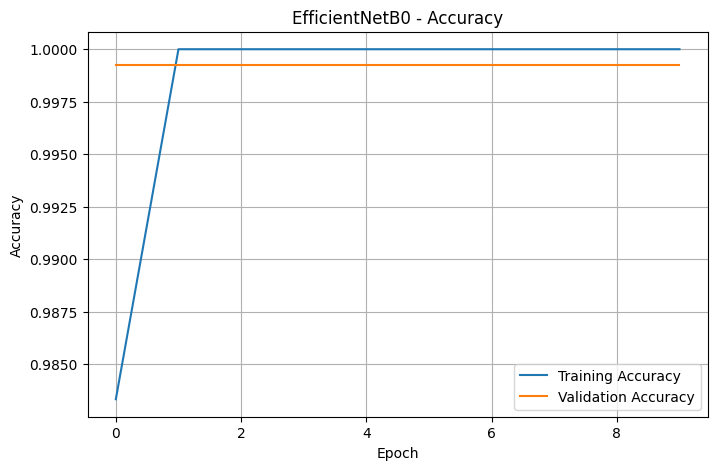

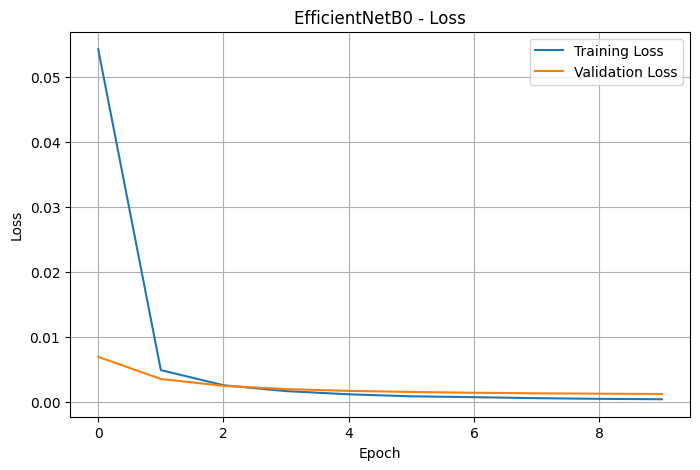

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("EfficientNetB0 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.savefig("/content/results/accuracy.png")
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("EfficientNetB0 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig("/content/results/loss.png")
plt.show()
